## Model Comparison Using Algorithm B1
# Plot AULD algorithm<br>
Model Comparison Using Algorithm B1
To assess whether differences in cross-validation performance between competing GEV formulations are statistically significant, we apply the randomization test of Auld et al. (2023, Algorithm B1). For each pair of models, observation-level score differences are computed from the five-fold cross-validation results. Under the null hypothesis that the two models are equally skillful, the score differences are exchangeable and their signs may be randomly permuted. A null distribution of mean score differences is generated using 10^5 random sign permutations, and a one-sided p-value is estimated as the proportion of randomized statistics greater than or equal to the observed mean score difference. Small p-values indicate statistical support for the model with the lower average score.

In [292]:
import numpy as np
import xarray as xr
from pathlib import Path
from itertools import combinations
import cartopy
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs
from matplotlib import cm
from matplotlib.transforms import blended_transform_factory

In [293]:
import warnings
warnings.filterwarnings('ignore')

In [294]:
state_borders =cartopy.feature.NaturalEarthFeature(category='cultural', name='admin_1_states_provinces_lakes', scale='50m', facecolor='none')
rivers = cartopy.feature.NaturalEarthFeature(category='physical',name='rivers_lake_centerlines',scale='50m',facecolor='none',edgecolor='blue')

In [295]:
latN = 50
latS = 25
lonW = -119.5
lonE = -74

cLat = (latN + latS)/2
cLon = (lonW + lonE )/2

In [296]:
proj = ccrs.LambertConformal(central_latitude=cLat, central_longitude=cLon)
proj_data = ccrs.PlateCarree()

In [297]:
# ============================================================
# INPUT FILES
# ============================================================
files = {"PrNO": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostLocSca_extremes_gev_1952_2025.nc",\
         "Pr14": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr14LocSca_extremes_gev_1952_2025.nc",
         "Pr30": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr30LocSca_extremes_gev_1952_2025.nc",
         #"Pr45": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr45LocSca_extremes_gev_1952_2025.nc",
         "Pr90": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr90LocSca_extremes_gev_1952_2025.nc",
         "Pr180": "/Users/gahe5417/data/TXx/NClimGrid_CONUS_TXx1_glostpr180LocSca_extremes_gev_1952_2025.nc"}

metrics = ["CRPS_cv","SE_cv","DawSeb_cv"]
models = list(files.keys())
models_name = {"PrNO": "$No Pr$","Pr14": r"$Pr_{14}$", "Pr30": r"$Pr_{30}$",  "Pr90": r"$Pr_{90}$", "Pr180": r"$Pr_{180}$"}
# ============================================================"Pr45": r"$Pr_{45}$",
# READ MODEL DATASETS
# ============================================================
datasets = {}
for model, file in files.items():
    print(f"Reading {model}")
    ds = xr.open_dataset(file)
    for metric in metrics:
        ds[metric] = (ds[metric].load())
    ds['AIC']= ds['AIC'].load()    
    ds['BIC']= ds['BIC'].load()    
    datasets[model] = ds
    return_periods = ds.return_periods.data
    ds.close()
    
AEP = [1/irp for irp in return_periods]
units = '°F'    
# ============================================================
# BUILD PAIR LIST
# ============================================================
pairs = list(combinations(models, 2))
print(pairs)
# ============================================================
# READ ALGORITHM B1 RESULTS
# ============================================================
b1_files = {}
for model0, model1 in pairs:
    file_B1 = (f"/Users/gahe5417/data/TXx/"f"AlgorithmB1_glostpr{model0[2::]}LocSca_vs_glostpr{model1[2::]}LocSca.nc")
    print(f"Reading {Path(file_B1).name}")
    b1_files[(model0, model1)] = xr.open_dataset(file_B1)

landmask = datasets["PrNO"].AIC.notnull()

Reading PrNO
Reading Pr14
Reading Pr30
Reading Pr90
Reading Pr180
[('PrNO', 'Pr14'), ('PrNO', 'Pr30'), ('PrNO', 'Pr90'), ('PrNO', 'Pr180'), ('Pr14', 'Pr30'), ('Pr14', 'Pr90'), ('Pr14', 'Pr180'), ('Pr30', 'Pr90'), ('Pr30', 'Pr180'), ('Pr90', 'Pr180')]
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr14LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr30LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostprNOLocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr30LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostpr14LocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr30LocSca_vs_glostpr90LocSca.nc
Reading AlgorithmB1_glostpr30LocSca_vs_glostpr180LocSca.nc
Reading AlgorithmB1_glostpr90LocSca_vs_glostpr180LocSca.nc


## Pairwise Comparison of Candidate Precipitation Covariates
To determine whether differences in predictive performance between precipitation covariates are statistically meaningful, we apply Algorithm B1 of Auld et al. (2023) to the cross-validation scores. For each pair of models, the mean score difference is computed and evaluated using a randomization test based on $10^5$ sign permutations. The resulting p-values are used to identify grid cells where one model significantly outperforms the other. Significant differences are shown in color, while nonsignificant differences are shown in gray.

In [307]:
def plot_algorithmB1_matrix(metric,datasets,b1_files,models=("Pr15", "Pr30", "Pr90", "Pr180"), alpha=0.05, proj=None, state_borders=None, rivers=None,):
    """
    Plot pairwise Algorithm B1 comparison matrix.
    Parameters
    ----------
    metric : str
        e.g. "CRPS_cv", "DawSeb_cv", "SE_cv"
    datasets : dict
        Dictionary of opened datasets:
        { "Pr15": ds15, "Pr30": ds30,... }
    b1_files : dict
        Dictionary containing Algorithm B1 outputs:
        b1_files[("Pr15","Pr30")] = xr.Dataset
        b1_files[("Pr15","Pr90")] = xr.Dataset
        ...
    alpha : float
        Significance level.
    proj : cartopy projection
    state_borders : cartopy feature
    rivers : cartopy feature
    """

    metric_name = metric.replace("_cv", "")
    # --------------------------------------------------
    # Color convention
    # -1 : row model significantly better
    #  0 : no significant difference
    # +1 : column model significantly better
    # --------------------------------------------------
    cmap = mcolors.ListedColormap([ "#d73027", "#d9d9d9",    "#4575b4"])
    norm = mcolors.BoundaryNorm([-1.5, -0.5, 0.5, 1.5],cmap.N)
    nmodels = len(models)
    
    fig, axes = plt.subplots(nmodels-1,nmodels,figsize=(16, 10),subplot_kw={"projection": proj},squeeze=False)
    plt.subplots_adjust(left=0.0,right=0.95,bottom=0.25,top=0.9,hspace=0.01,wspace=0.04,)
    # --------------------------------------------------
    # Hide everything initially
    # --------------------------------------------------
    for i in range(nmodels-1):
        for j in range(nmodels):
            axes[i, j].set_visible(False)
    # --------------------------------------------------
    # Fill upper triangle
    # --------------------------------------------------
    for i, row_model in enumerate(models[:-1]):
        for j, col_model in enumerate(models):
            if j <= i:
                continue
            ax = axes[i, j]
            ax.set_visible(True)
            ds0 = datasets[row_model]
            ds1 = datasets[col_model]
            ds_b1 = b1_files[(row_model, col_model)]
            mean_diff = (ds0[metric].mean("time") - ds1[metric].mean("time"))
            pval = ds_b1[f"{metric_name}_B1_pvalue"]
            comparison = xr.full_like(mean_diff, np.nan)
            # +1 = column model wins
            comparison = xr.where((pval <= alpha) & (mean_diff > 0),1,comparison,)
            # -1 = row model wins
            comparison = xr.where((pval <= alpha) & (mean_diff < 0), -1,comparison)
            # 0 = no significant difference
            comparison = xr.where(pval > alpha, 0,comparison)
            # --------------------------------------------------
            # Area-weighted CONUS percentages (cos(lat) weighting)
            # --------------------------------------------------
            # Detect latitude coordinate name ("lat" or "latitude")
            lat_name = "lat" if "lat" in comparison.dims else "latitude"
            weights = np.cos(np.deg2rad(comparison[lat_name]))

            valid = np.isfinite(comparison)
            total_valid_area = weights.where(valid).sum().item()

            pct_row = (100.0 * (comparison == -1).weighted(weights).sum().item()/ total_valid_area)
            pct_col = (100.0 * (comparison ==  1).weighted(weights).sum().item()/ total_valid_area)
            # --------------------------------------------------
            # Plot
            # --------------------------------------------------     
            comparison.plot(ax=ax,transform=ccrs.PlateCarree(),cmap=cmap,norm=norm,add_colorbar=False)
            ax.coastlines(linewidth=0.3)    
            if state_borders is not None:
                ax.add_feature(state_borders, edgecolor="k",linewidth=0.1,zorder=100)
            if rivers is not None:
                ax.add_feature(rivers,edgecolor="royalblue",linewidth=0.2)
            ax.set_title(f"{pct_row:.1f}% / {pct_col:.1f}%",fontsize=14)
            ax.set_title(f"",fontsize=14)
            #ax.text(0.12, 0.03, f"{pct_row:.1f}%",transform=ax.transAxes, ha="right", va="bottom",fontsize=12, fontweight="bold", color="#d73027")
            #ax.text(0.15, 0.03, "/",transform=ax.transAxes, ha="center", va="bottom",fontsize=12, color="#555555")
            ax.text(0.03, 0.03, f"{pct_col:.1f}%",transform=ax.transAxes, ha="left", va="bottom",fontsize=12, fontweight="bold", color="#4575b4")
            ax.set_xticks([])
            ax.set_yticks([])   
            ax.set_xlabel('')
            ax.set_ylabel('')   
    # --------------------------------------------------
    # Diagonal labels
    # --------------------------------------------------
    for i, model in enumerate(models[:-1]):
        ax = axes[i, i]
        ax.set_visible(True)
        ax.text(0.5,0.5,models_name[model],ha="center",va="center",fontsize=18,fontweight="bold",transform=ax.transAxes)
        ax.set_axis_off()
    # --------------------------------------------------
    # Lower triangle blank
    # --------------------------------------------------
    for i in range(nmodels-1):
        for j in range(i):
            axes[i, j].set_visible(True)
            axes[i, j].set_axis_off()
    # --------------------------------------------------
    # Column labels
    # --------------------------------------------------
    for j in range(1, len(models)):
       axes[0, j].text(0.5,1.18,models_name[models[j]],transform=axes[0, j].transAxes,ha="center",fontsize=18,fontweight="bold",)
    # --------------------------------------------------
    # Row labels
    # --------------------------------------------------
    #for i in range(len(models) - 1):
    #    axes[i, i+1].text(-0.20,0.5,models[i],rotation=90,transform=axes[i, i+1].transAxes,ha="center",va="center",fontsize=14,fontweight="bold")
    # --------------------------------------------------
    # Colorbar
    # --------------------------------------------------
    cbar_ax = fig.add_axes([0.1, 0.15, 0.8, 0.04])
    cbar = plt.colorbar(plt.cm.ScalarMappable(cmap=cmap,norm=norm,),cax=cbar_ax,orientation="horizontal",ticks=[-1, 0, 1])
    cbar.ax.set_xticklabels([ "Row model better", "No significant difference","Column model better" ],fontsize=14)
    # --------------------------------------------------
    # Title
    # --------------------------------------------------
    fig.text(0.5,0.225,"CONUS area won: Column model",ha="center",fontsize=16)
    fig.suptitle(f"Algorithm B1 Pairwise Model Comparison ({metric_name})",fontsize=20,fontweight="bold")
    
    return fig

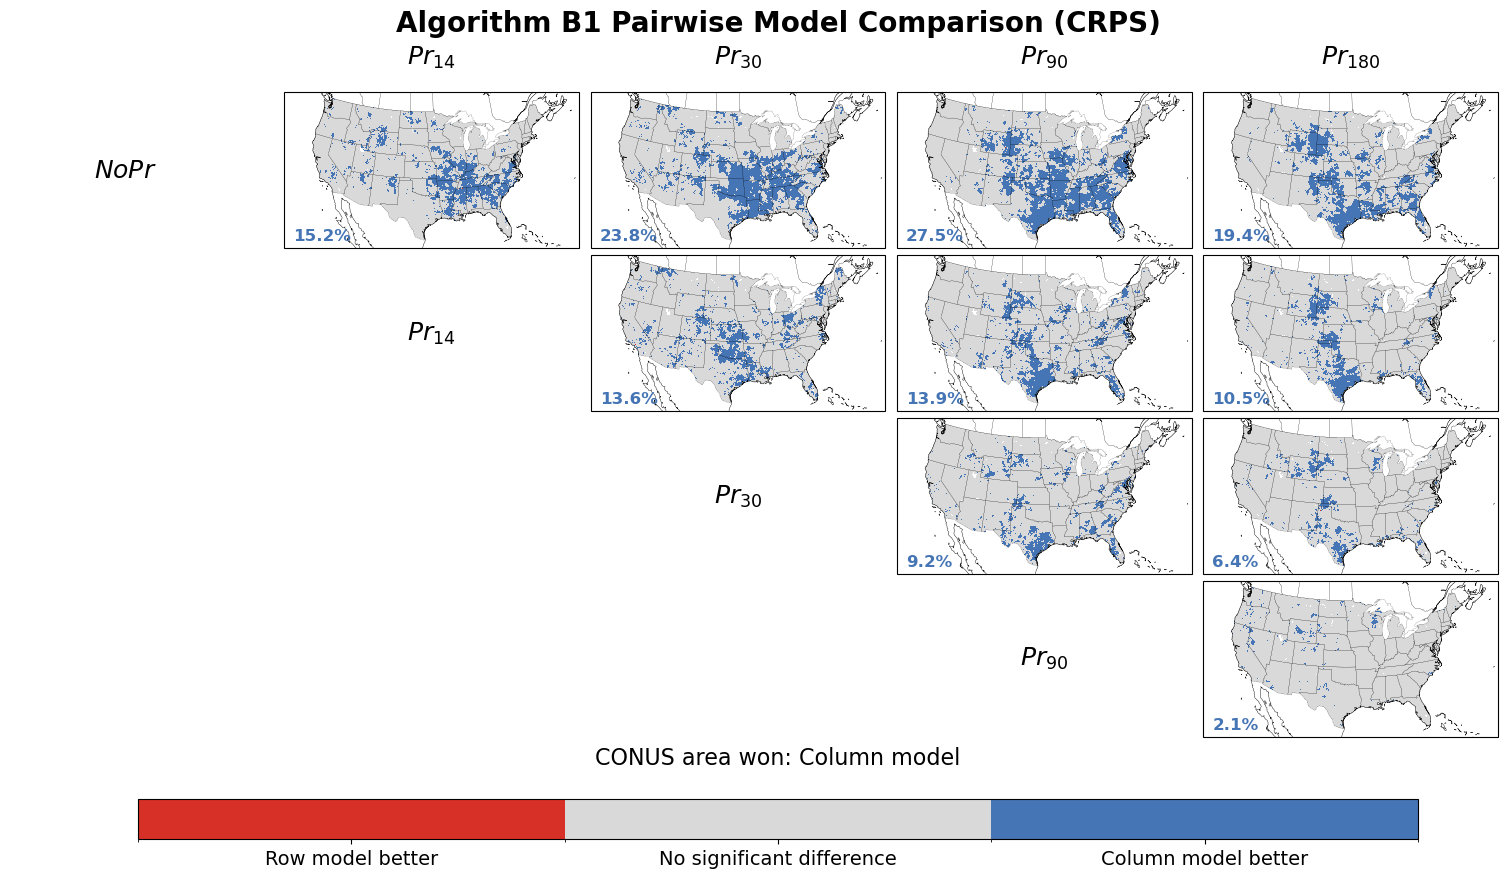

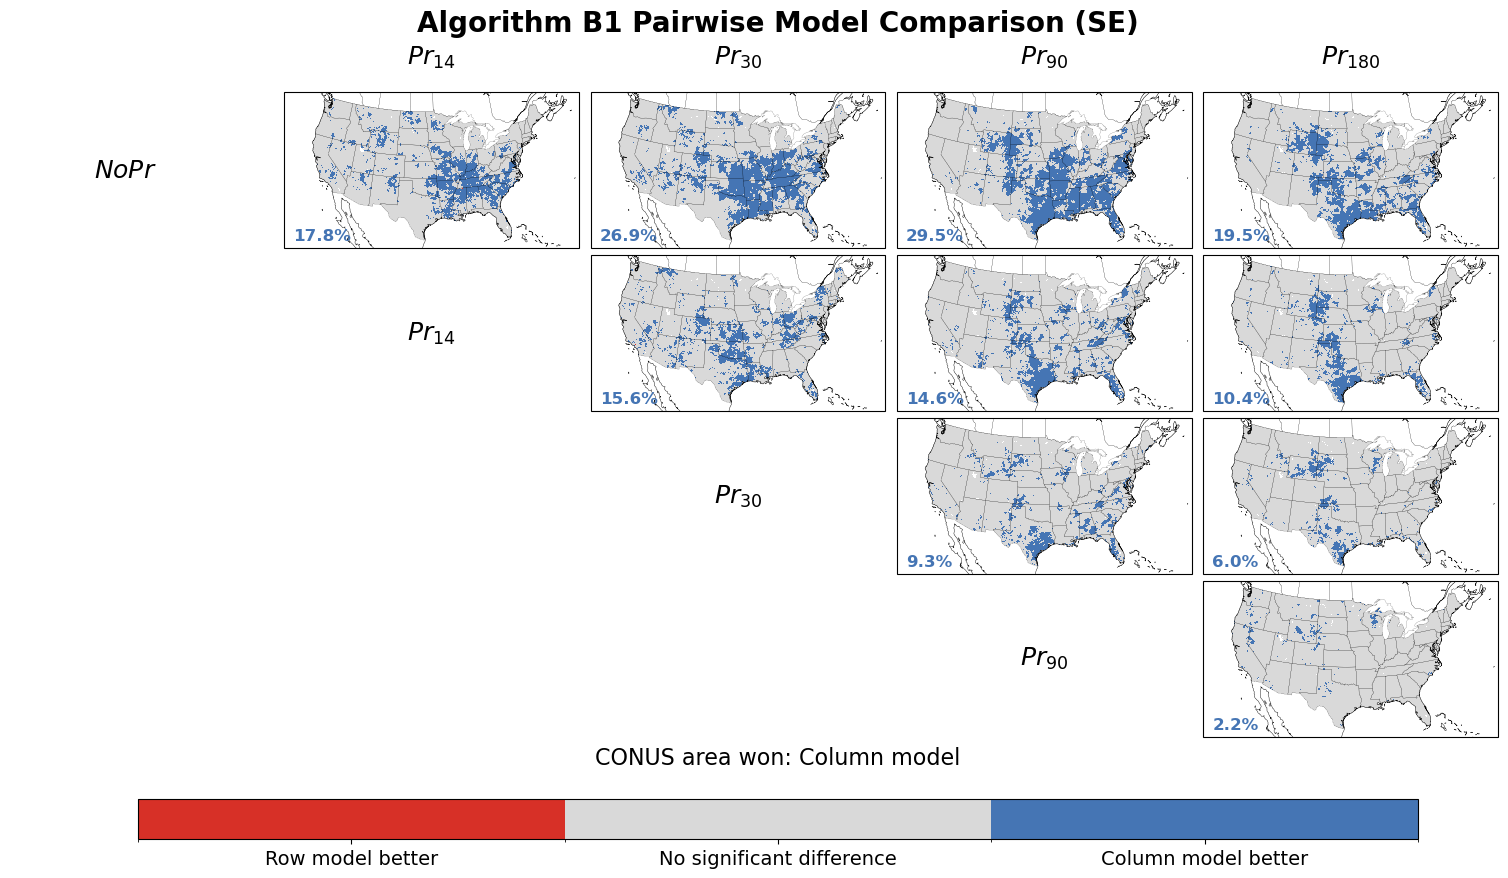

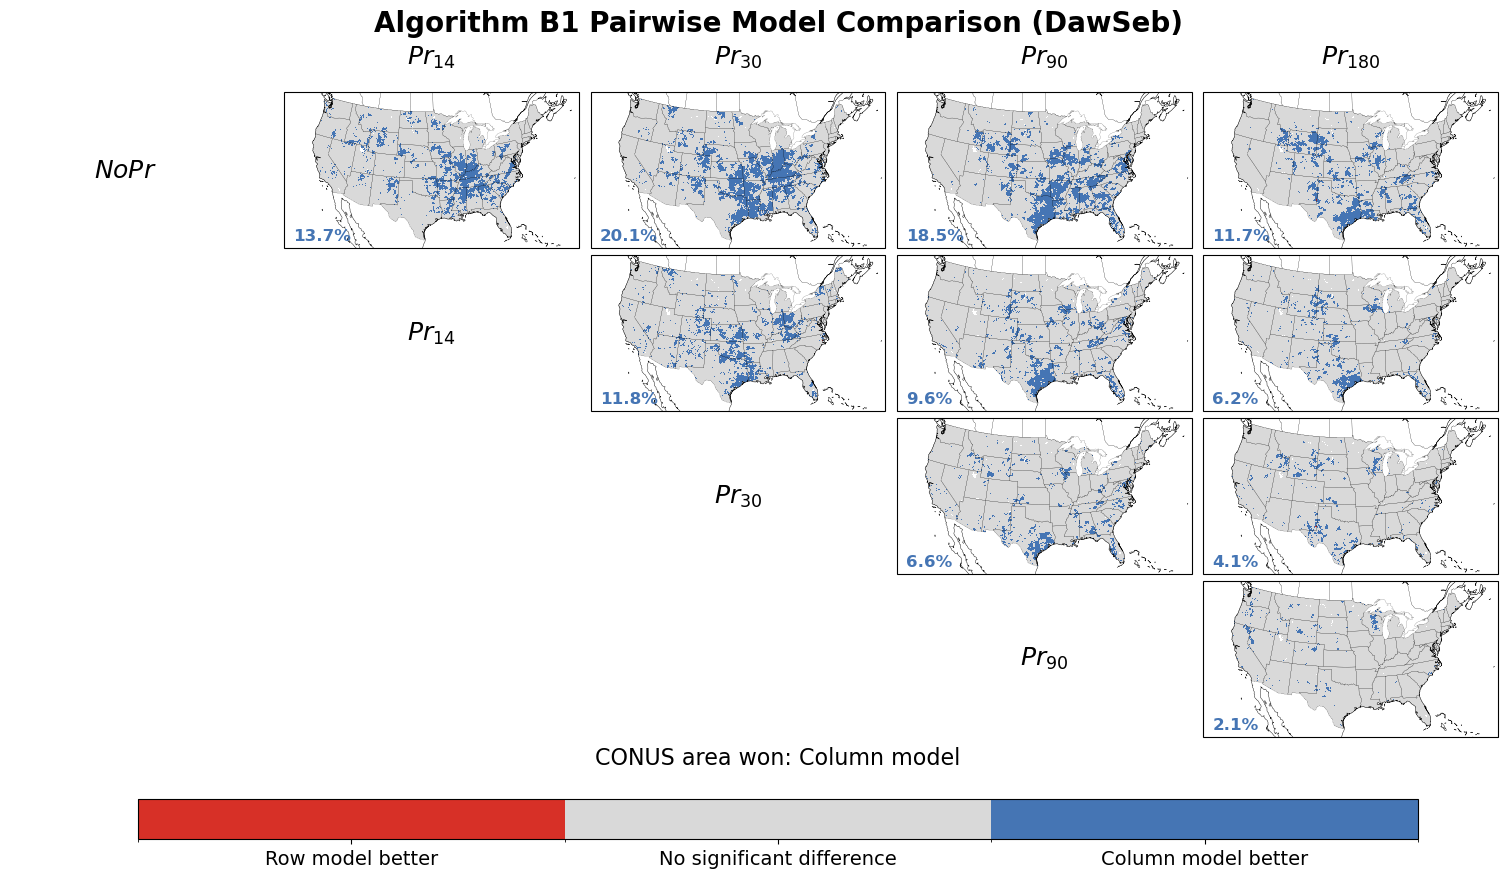

In [299]:
for metric in ["CRPS_cv", "SE_cv","DawSeb_cv"]:# ,"DawSeb_cv", "SE_cv"
    fig = plot_algorithmB1_matrix(metric=metric, datasets=datasets,b1_files=b1_files,models=models, alpha=0.05,proj=proj,state_borders=state_borders,rivers=None)
    plt.show()

*Figure. Pairwise Algorithm B1 comparisons of competing precipitation covariates. Blue shading indicates locations where the column model significantly outperforms the row model ($p \le 0.05$); red shading indicates locations where the row model significantly outperforms the column model; gray indicates no statistically significant difference. Percentages reported within each panel correspond to the fraction of the CONUS area where the column model is significantly preferred.*

In [308]:
model_ids = {"PrNO": 1,"Pr14": 2,"Pr30": 3,"Pr90": 4,"Pr180": 5}

## Dominant Precipitation Covariate Based on Predictive Skill
While pairwise comparisons identify significant differences between individual model pairs, a synthesis is required to determine the overall preferred precipitation covariate at each location.

For a given metric, each model receives one victory for every statistically significant pairwise comparison in which its score is lower than that of its competitor. The number of significant victories is then accumulated across all competing models. Models with the greatest number of victories become candidates for dominance.

When multiple candidates achieve the same number of significant victories, the tie is resolved using the average score itself, with preference given to the model having the lowest mean score. Locations where no model achieves a statistically significant victory are classified as No Winner.

In [309]:
def dominant_model_map(metric,datasets, b1_files, models, alpha=0.05):
    """
    Dominant model based on pairwise Algorithm B1 tests.
    Returns
    1. Count significant pairwise victories (Algorithm B1).
    2. Model(s) with the most wins become candidates.
    3. If several candidates are tied, select the candidate with
       the lowest mean score.
    4. If no model achieves any significant victory, assign 0.
    -------
    dominant :  xr.DataArray(dtype=str)
    """
    metric_name = metric.replace("_cv", "")
    # --------------------------------------------------
    # Mean metric scores
    # --------------------------------------------------
    scores = xr.concat([datasets[m][metric].mean("time") for m in models],dim="model")
    scores = scores.assign_coords(model=models)    
    wins = xr.zeros_like(scores, dtype=np.int16)
    # --------------------------------------------------
    # Count pairwise victories
    # --------------------------------------------------
    for i, model_i in enumerate(models):
        score_i = datasets[model_i][metric].mean("time")
        for j, model_j in enumerate(models):
            if j <= i:
                continue
            score_j = datasets[model_j][metric].mean("time")
            pair = (model_i, model_j)
            ds_b1 = b1_files[pair]
            pval = ds_b1[f"{metric_name}_B1_pvalue"]
            sig = pval <= alpha
            i_wins = sig & (score_i < score_j)
            j_wins = sig & (score_j < score_i)
            wins.loc[dict(model=model_i)] += i_wins.astype(np.int16)
            wins.loc[dict(model=model_j)] += j_wins.astype(np.int16)
    # --------------------------------------------------
    # Determine candidates
    # --------------------------------------------------
    max_wins = wins.max("model")
    candidates = wins == max_wins
    # score used for non-candidates
    dummy_score = float(scores.max( skipna=True) ) + 1
    candidate_scores = xr.where(candidates,  scores, dummy_score)
    # replace remaining NaNs (all-NaN locations)
    candidate_scores = candidate_scores.fillna(dummy_score)
    # tied candidate with lowest score wins
    dominant = candidate_scores.argmin("model").astype(np.int16) + 1
    # no winner if nobody achieved a significant victory
    dominant = xr.where( max_wins == 0, 0,dominant  )
    # --------------------------------------------------
    # Metadata
    # --------------------------------------------------
    dominant.attrs["long_name"] = ( f"Dominant model ({metric_name})")
    dominant.attrs["flag_values"] = ([0] + list(range(1, len(models) + 1)))
    dominant.attrs["flag_meanings"] = ("NoWin " + " ".join(models))

    return dominant

In [310]:
dominant_CRPS = dominant_model_map("CRPS_cv",datasets,b1_files,models,alpha=0.05)
dominant_DawSeb = dominant_model_map("DawSeb_cv",datasets,b1_files,models,alpha=0.05)
dominant_SE = dominant_model_map("SE_cv",datasets,b1_files,models,alpha=0.05)

In [311]:
dom_stack = xr.concat([dominant_CRPS,dominant_DawSeb,dominant_SE],dim="metric")

In [312]:
from scipy.stats import mode
def majority_vote(x):
    x = x[x > 0]
    if len(x) == 0:
        return 0
    vals, counts = np.unique(x, return_counts=True)
    if counts.max() < 2:
        return 0
    return vals[counts.argmax()]

def majority_vote_no_nothing(x):
    """
    Majority vote among valid model selections.
    Assumes:
        0 = NoWin
    Returns:
        NaN if no consensus.
    """
    x = x[x > 0]
    if len(x) == 0:
        return np.nan
    vals, counts = np.unique(x, return_counts=True)
    max_count = counts.max()
    winners = vals[counts == max_count]
    # tie among winners
    if len(winners) > 1:
        return np.nan
    return winners[0]

def agreement_count(x):
    # remove no-winner class
    x = x[x > 0]
    if len(x) == 0:
        return 0
    vals, counts = np.unique( x, return_counts=True )
    return counts.max()

In [313]:
consensus_map = xr.apply_ufunc(majority_vote,dom_stack,input_core_dims=[["metric"]],vectorize=True,output_dtypes=[int])
agreement_map = xr.apply_ufunc(agreement_count,dom_stack,input_core_dims=[["metric"]],vectorize=True,output_dtypes=[np.int16])
agreement_map = agreement_map.where(landmask)
consensus_map = consensus_map.where(landmask)

In [314]:
def plot_categorical_map(da, title,cmap,norm,cbar_labels,ax=None, proj=None,state_borders=None,rivers=None,\
                    show_colorbar=True,show_percentages=True,extent=(-125, -66.5, 24, 50)):
    """
    Generic categorical map plotting function.
    Parameters
    ----------
    da : xr.DataArray
        Categorical map.
    title : str
    cmap : matplotlib colormap
    norm : matplotlib.colors.BoundaryNorm
    cbar_labels : list of str
        Labels corresponding to categories.
    ax : matplotlib axis, optional
    show_colorbar : bool, default=True
    show_percentages : bool, default=True
        Display area-weighted percentages.
    """
    # --------------------------------------------------
    # Figure / Axis
    # --------------------------------------------------
    created_fig = False
    if ax is None:
        fig = plt.figure(figsize=(13, 7))
        ax = plt.axes(projection=proj)
        created_fig = True
    else:
        fig = ax.figure
    da.plot(ax=ax, transform=ccrs.PlateCarree(),cmap=cmap, norm=norm, add_colorbar=False)
    # --------------------------------------------------
    # Map features
    # --------------------------------------------------
    ax.coastlines(linewidth=0.3)
    if state_borders is not None:
        ax.add_feature( state_borders, edgecolor="k",linewidth=0.1,zorder=100)
    if rivers is not None:
        ax.add_feature(rivers, edgecolor="royalblue",linewidth=0.2)
    ax.set_extent( extent,crs=ccrs.PlateCarree() )
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlabel('')
    ax.set_ylabel('')
    # --------------------------------------------------
    # Area percentages
    # --------------------------------------------------
    if show_percentages:
        lat_name = ( "lat"if "lat" in da.coords else "latitude")
        weights = np.cos(np.deg2rad(da[lat_name]))

        total_area = weights.where( np.isfinite(da)).sum().item()
        txt = []
        for iclass, label in enumerate(cbar_labels):
            pct = ( 100 * (da == iclass).weighted(weights).sum().item()/ total_area)
            txt.append(f"{label.replace(chr(10),' ')}: {pct:.1f}%")

        ax.text(0.02,0.02, "\n".join(txt), transform=ax.transAxes,fontsize=11,fontweight="bold",va="bottom", ha="left",bbox=dict(facecolor="white",alpha=0.85,edgecolor="none"))
    # --------------------------------------------------
    # Colorbar
    # --------------------------------------------------
    if show_colorbar:
        ticks = (np.diff(norm.boundaries)/2+ norm.boundaries[:-1])
        cbar = plt.colorbar( plt.cm.ScalarMappable(  cmap=cmap,norm=norm,),ax=ax,orientation="horizontal",pad=0.06,shrink=0.85,ticks=ticks)
        cbar.ax.set_xticklabels(cbar_labels)
        cbar.ax.tick_params(labelsize=12)
        cbar.set_label( "Consensus dominant precipitation covariate",fontsize=14)
    # --------------------------------------------------
    # Title
    # --------------------------------------------------
    ax.set_title(title, fontsize=18,fontweight="bold")

    return fig,ax

## Preferred Precipitation Covariate from Cross-Validated CRPS
The primary model-selection result is based on CRPS because CRPS is a proper scoring rule that evaluates the full predictive distribution and is generally regarded as the most comprehensive measure of probabilistic forecast performance. The dominant-covariate map below therefore represents the primary precipitation-covariate recommendation.

(<Figure size 1300x700 with 2 Axes>,
 <GeoAxes: title={'center': 'Dominant Model (CRPS)'}>)

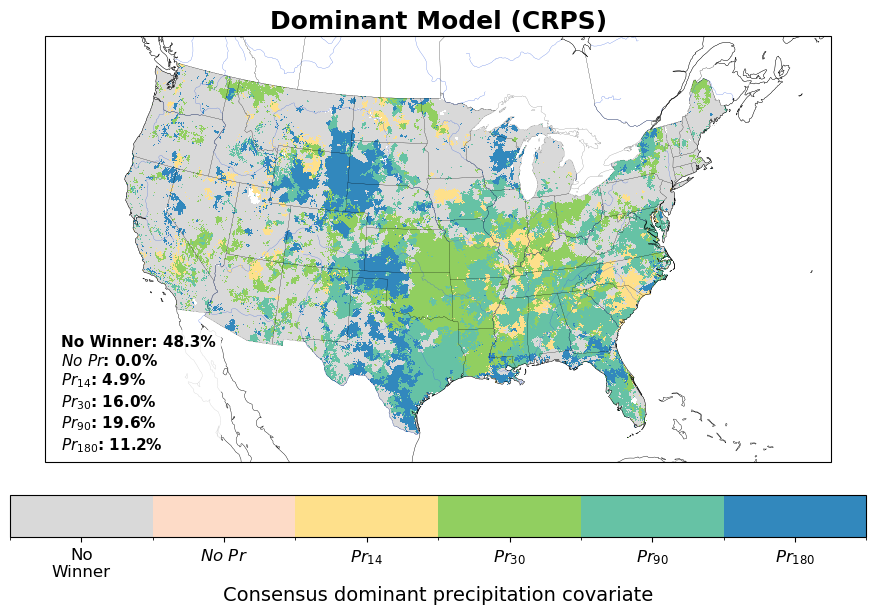

In [315]:
dominant_cmap = mcolors.ListedColormap([
    "#d9d9d9",
    "#fddbc7",
    "#fee08b",
   # "#d9ef8b",
    "#91cf60",
    "#66c2a5",
    "#3288bd",
])
dominant_labels = [
    "No\nWinner",
    "$No$ $Pr$",
    "$Pr_{14}$",
    "$Pr_{30}$",
    #"$Pr_{45}$",
    "$Pr_{90}$",
    "$Pr_{180}$",
]

dominant_norm = mcolors.BoundaryNorm(np.arange(-0.5, len(dominant_labels) + 0.5, 1), dominant_cmap.N,)

plot_categorical_map( dominant_CRPS.where(landmask),title="Dominant Model (CRPS)", cmap=dominant_cmap,norm=dominant_norm, cbar_labels=dominant_labels, proj=proj,state_borders=state_borders,rivers=rivers)

*Figure. Dominant precipitation covariate identified from cross-validated CRPS. At each grid cell, the selected covariate corresponds to the model with the greatest number of significant Algorithm B1 victories. Ties are resolved using the lowest mean CRPS. Gray indicates locations where no model achieves a statistically significant advantage.*

## Agreement Among Predictive Performance Metrics
Model-selection conclusions can depend on the metric used to evaluate predictive performance. To assess the robustness of the dominant-covariate classification, agreement is evaluated across three complementary predictive metrics: CRPS, Dawid-Sebastiani score, and squared error.

Agreement among metrics provides a measure of confidence in the selected precipitation covariate. Regions where multiple metrics identify the same dominant covariate indicate that model preference is relatively insensitive to the choice of verification metric.

(<Figure size 1300x700 with 2 Axes>,
 <GeoAxes: title={'center': 'Agreement Among CRPS, Dawid-Sebastiani, and Squared Error'}>)

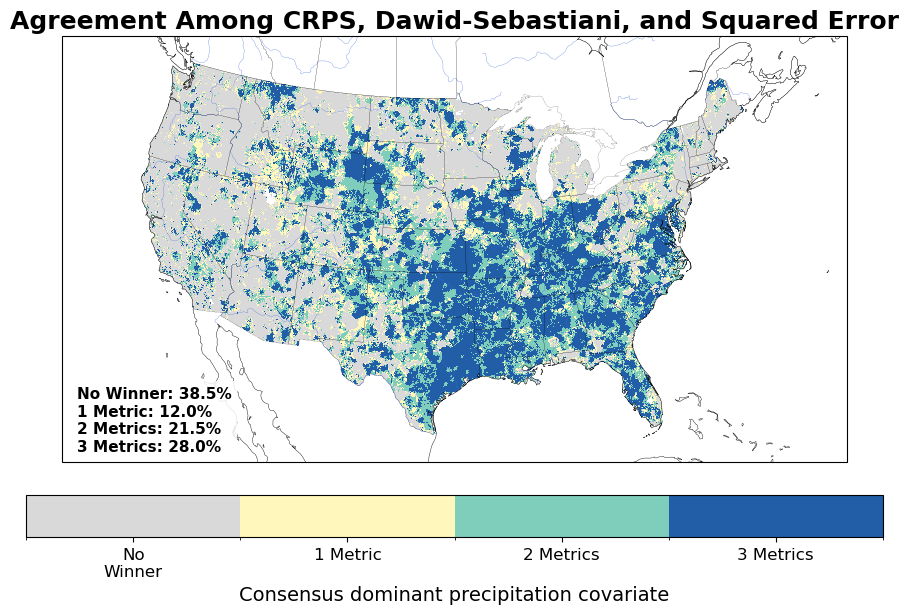

In [316]:
agreement_cmap = mcolors.ListedColormap(["#d9d9d9",  # No winner
    "#fff7bc",  # 1 metric
    "#7fcdbb",  # 2 metrics
    "#225ea8"])

agreement_norm = mcolors.BoundaryNorm( [-0.5, 0.5, 1.5, 2.5, 3.5], agreement_cmap.N)

agreement_labels = ["No\nWinner",
    "1 Metric",
    "2 Metrics",
    "3 Metrics"]

plot_categorical_map(agreement_map.where(landmask), title="Agreement Among CRPS, Dawid-Sebastiani, and Squared Error",\
    cmap=agreement_cmap, norm=agreement_norm, cbar_labels=agreement_labels,proj=proj,state_borders=state_borders,rivers=rivers)

#Figure. Agreement among CRPS, Dawid-Sebastiani score, and squared error. Values indicate the number of predictive metrics selecting the same dominant precipitation covariate at each grid cell. Greater agreement implies increased confidence that the identified precipitation accumulation period represents a robust improvement in predictive performance.#

## Information-Theoretic Model Selection
Predictive metrics quantify out-of-sample prediction skill, whereas information criteria evaluate model fit while penalizing model complexity. To investigate whether conclusions based on predictive verification are consistent with likelihood-based model selection, dominant-covariate maps are also constructed using the minimum Akaike Information Criterion (AIC) and Bayesian Information Criterion (BIC).

Unlike the predictive-skill analysis, these classifications are based solely on model fit and do not incorporate Algorithm B1 significance testing.

In [317]:
def dominant_model_minimum( metric, datasets, models,landmask):
    """
    Dominant model based solely on minimum metric value.
    Used for AIC and BIC.
    """
    scores = xr.concat([datasets[m][metric]for m in models],dim="model")
    scores = scores.assign_coords( model=models)
    dummy_score = float(np.nanmax(scores.values)) + 1
    scores = scores.fillna(dummy_score)
    dominant = scores.argmin("model").astype(np.int16) + 1
    dominant = dominant.where(landmask,  0)

    dominant.attrs["long_name"] = (f"Best model ({metric})")
    dominant.attrs["flag_values"] = ([0] + list(range(1, len(models)+1)))
    dominant.attrs["flag_meanings"] = ( "NoWin " + " ".join(models))

    return dominant

In [318]:
dominant_AIC = dominant_model_minimum( "AIC",datasets, models,landmask)
dominant_BIC = dominant_model_minimum("BIC",datasets,models,landmask)

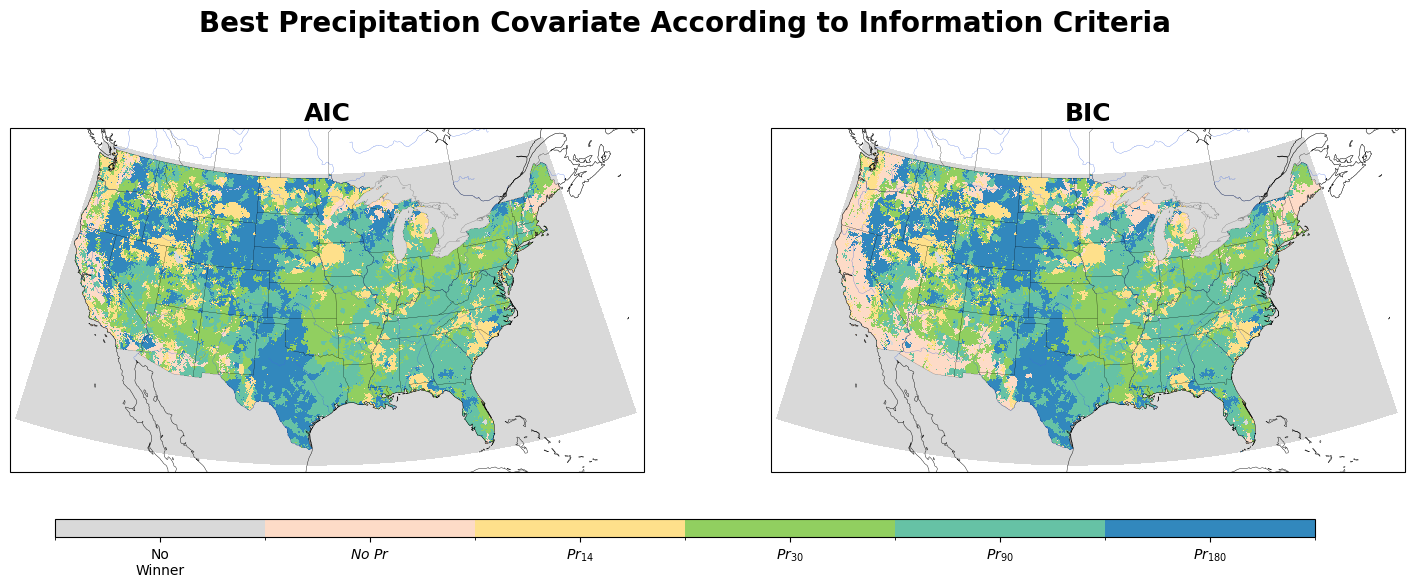

In [319]:
fig, axes = plt.subplots( 1, 2,figsize=(18, 6),subplot_kw={"projection": proj})

plot_categorical_map( dominant_AIC, title="AIC", cmap=dominant_cmap, norm=dominant_norm, cbar_labels=dominant_labels, ax=axes[0],
    state_borders=state_borders, rivers=rivers, show_colorbar=False, show_percentages=False)

plot_categorical_map( dominant_BIC, title="BIC", cmap=dominant_cmap, norm=dominant_norm, cbar_labels=dominant_labels, ax=axes[1],
    state_borders=state_borders, rivers=rivers, show_colorbar=False, show_percentages=False)

cax = fig.add_axes([0.15, 0.10, 0.70, 0.03])
ticks = ( np.diff(dominant_norm.boundaries) / 2 + dominant_norm.boundaries[:-1])
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=dominant_cmap,norm=dominant_norm), cax=cax, orientation="horizontal", ticks=ticks)

cb.ax.set_xticklabels(dominant_labels)
plt.suptitle("Best Precipitation Covariate According to Information Criteria", fontsize=20, fontweight="bold")
plt.show()

*Figure. Dominant precipitation covariate according to information criteria. Panels show the precipitation covariate associated with the minimum AIC (left) and minimum BIC (right) at each grid cell. These information-theoretic classifications provide an independent assessment of preferred precipitation accumulation periods based on model fit and complexity.*

## Agreement Between Cross-Validated CRPS and Information Criteria
CRPS is used as the primary model-selection metric because it evaluates the full predictive distribution and provides a comprehensive measure of out-of-sample predictive performance. To assess whether conclusions based on predictive skill are supported by traditional model-selection criteria, the dominant precipitation covariate identified from CRPS is compared against a consensus classification derived from AIC and BIC.

Agreement between these independent approaches suggests that the selected precipitation covariate improves both predictive skill and overall model fit. Disagreement highlights locations where models that optimize forecasting performance differ from those favored by information-theoretic criteria.

In [320]:
ic_stack = xr.concat([dominant_AIC,dominant_BIC,],dim="metric")
ic_consensus = xr.apply_ufunc( majority_vote_no_nothing,ic_stack, input_core_dims=[["metric"]],vectorize=True, output_dtypes=[float])

In [321]:
crps_vs_ic = xr.where(np.isfinite(ic_consensus), dominant_CRPS == ic_consensus, np.nan)
crps_vs_ic = crps_vs_ic.where(landmask)
crps_vs_ic = xr.where(crps_vs_ic,1,0,)

(<Figure size 1300x700 with 2 Axes>,
 <GeoAxes: title={'center': 'CRPS vs AIC/BIC Agreement'}>)

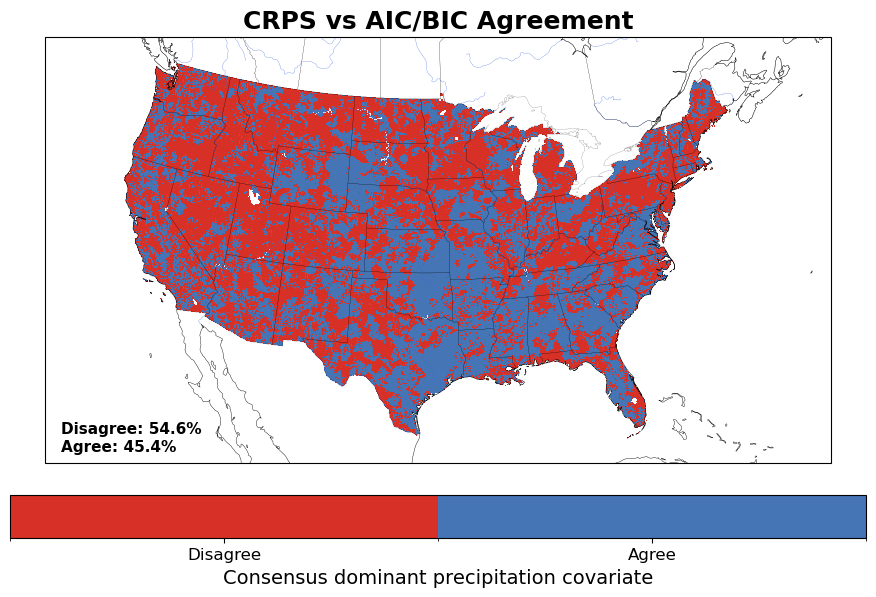

In [322]:
compare_cmap = mcolors.ListedColormap([
    "#d73027",  # disagreement
    "#4575b4",  # agreement
])
compare_norm = mcolors.BoundaryNorm([-0.5, 0.5, 1.5],compare_cmap.N)
compare_labels = ["Disagree","Agree"]
plot_categorical_map( crps_vs_ic.where(landmask),title="CRPS vs AIC/BIC Agreement",
    cmap=compare_cmap,norm=compare_norm,cbar_labels=compare_labels,proj=proj,state_borders=state_borders,rivers=rivers)

*Figure. Agreement between cross-validated CRPS and information-theoretic model selection. Blue regions indicate locations where the dominant precipitation covariate identified from CRPS matches the consensus covariate selected by AIC and BIC. Red regions indicate disagreement between predictive-skill-based and likelihood-based model selection. Agreement suggests that the preferred precipitation accumulation period improves both out-of-sample predictive performance and in-sample model fit.*

############################################################################
## Not from me and didn't check anything yet. I will do that tomorrow.
############################################################################

(<Figure size 1300x700 with 2 Axes>,
 <GeoAxes: title={'center': 'Dominant Model (CRPS)'}>)

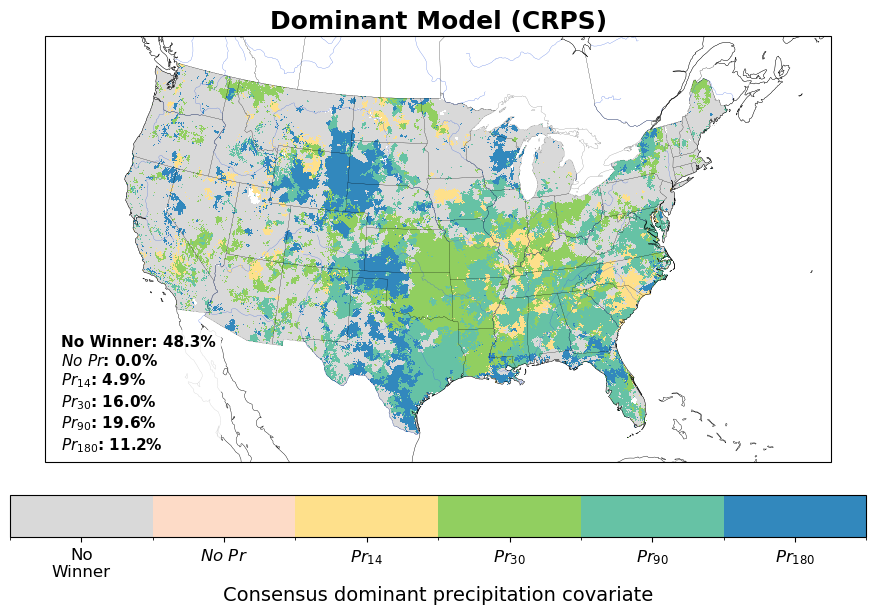

In [323]:
plot_categorical_map( dominant_CRPS.where(landmask),title="Dominant Model (CRPS)", cmap=dominant_cmap,norm=dominant_norm, cbar_labels=dominant_labels, proj=proj,state_borders=state_borders,rivers=rivers)


## Hypothesized Explanatory Controls of Dominant Precipitation Covariates
The spatial distribution of dominant precipitation accumulation periods appears to reflect large-scale hydroclimatic gradients across the continental United States. Several physically based mechanisms may contribute to the observed patterns.

# Hydroclimatic moisture availability (strong evidence)
Longer accumulation periods ($Pr_{90}$–$Pr_{180}$) occur primarily across the humid Southeast, Gulf Coast, eastern Texas, and portions of the northern Great Plains. These regions coincide with areas of high mean annual precipitation, suggesting that precipitation influences temperature extremes through long-term moisture-storage processes rather than through individual weather events (Seneviratne et al., 2010; Mueller and Seneviratne, 2012).

# Soil-moisture memory and land-atmosphere coupling (strong evidence)
Multi-month precipitation accumulations may act as proxies for antecedent soil-moisture conditions. In humid regions, stored soil moisture can influence evapotranspiration and surface energy partitioning over periods of several weeks to months, thereby modulating warm-temperature extremes. Similar land-atmosphere coupling mechanisms have been identified as key drivers of heat extremes in transitional and moisture-limited climates (Koster et al., 2004; Seneviratne et al., 2010; Miralles et al., 2019).

# Subseasonal drought development (moderate evidence)
Intermediate accumulation periods ($Pr_{30}$–$Pr_{45}$) dominate much of the central United States, including the southern Great Plains, lower Midwest, and Mississippi Valley. These time scales are consistent with the evolution of flash drought and subseasonal soil-moisture deficits, suggesting that extreme temperatures may be linked to precipitation anomalies accumulated over approximately one month (Ford and Labosier, 2017; Otkin et al., 2018).

# Topographic controls and snow-related processes (moderate evidence)
Large areas of the Rocky Mountains, Sierra Nevada, and Intermountain West are classified as No Winner. These regions correspond closely to areas of complex terrain and high elevation, suggesting that temperature extremes may be influenced more strongly by elevation, snowpack variability, downslope flow, and large-scale circulation than by accumulated precipitation (Daly et al., 2008; Pepin et al., 2015).

# Seasonal water storage and recharge processes (speculative)
The occurrence of $Pr_{180}$ dominance in parts of the northern Great Plains may reflect influences from winter snow accumulation, spring recharge, groundwater storage, or long-term soil-moisture persistence. These processes operate on seasonal time scales and could explain the preference for six-month precipitation accumulations (Entin et al., 2000; Seneviratne et al., 2010).

# Land use and vegetation effects (weak evidence from the present analysis)
The dominant-covariate patterns do not appear to align strongly with major land-cover boundaries alone. While agricultural regions may contribute to the prevalence of $Pr_{30}$–$Pr_{45}$ in the central United States through enhanced soil-moisture feedbacks, the observed patterns are generally broader and more consistent with regional climate and hydrologic regimes than with individual land-use classes (Koster et al., 2004; Miralles et al., 2019).

# Working Hypothesis
Overall, the dominant precipitation accumulation period appears to increase with regional hydroclimatic memory. Humid regions characterized by strong soil-moisture storage and evapotranspiration tend to favor longer precipitation accumulations ($Pr_{90}$–$Pr_{180}$), whereas transitional climates of the central United States favor intermediate accumulations ($Pr_{30}$–$Pr_{45}$). Areas of complex terrain frequently exhibit no dominant precipitation covariate, suggesting weaker coupling between local precipitation accumulation and warm-temperature extremes. This interpretation is broadly consistent with previous studies linking temperature extremes to antecedent soil moisture, drought development, and land-atmosphere coupling (Koster et al., 2004; Seneviratne et al., 2010; Mueller and Seneviratne, 2012; Miralles et al., 2019).

## Future Figures to Test the Physical Controls of Dominant Precipitation Covariates
The current analysis identifies spatially coherent dominant precipitation accumulation periods but does not directly determine the physical mechanisms responsible for these patterns. The following analyses would provide quantitative tests of the proposed hypotheses.

# Figure 6. Dominant Precipitation Covariate and Mean Annual Precipitation
Hypothesis: Regions with higher climatological precipitation favor longer precipitation accumulation periods because of increased hydroclimatic memory.

Panels

(a) Dominant precipitation covariate (CRPS)
(b) Mean annual precipitation climatology
(c) Boxplots of annual precipitation grouped by dominant covariate class
Expected result

Mean annual precipitation increases systematically from $Pr_{14}$ to $Pr_{180}$.
Long accumulation periods are concentrated in humid regions of the eastern and southeastern United States.
Draft caption

Figure 6. Relationship between dominant precipitation covariates and mean annual precipitation. Regions where long accumulation periods ($Pr_{90}$–$Pr_{180}$) are selected generally coincide with humid climates, whereas shorter accumulation periods occur in drier transitional regions. Boxplots quantify the distribution of annual precipitation associated with each dominant covariate and provide a direct test of the hydroclimatic-memory hypothesis.

# Figure 7. Dominant Precipitation Covariate and Aridity Index
Hypothesis: Dominant accumulation period increases with climatic moisture availability.

Panels

(a) Dominant precipitation covariate
(b) Aridity Index ($P/PET$)
(c) Mean aridity index by dominant covariate class
Expected result

Humid environments preferentially select $Pr_{90}$–$Pr_{180}$.
Arid environments preferentially select $Pr_{30}$, $Pr_{14}$, or exhibit no dominant covariate.
Draft caption

Figure 7. Relationship between dominant precipitation covariates and climatic aridity. Longer accumulation periods are expected in humid regions where precipitation anomalies persist through soil-moisture storage and evapotranspiration feedbacks, whereas shorter accumulation periods are expected in moisture-limited environments.

# Figure 8. Dominant Precipitation Covariate and Soil Moisture Climatology
Hypothesis: The dominant accumulation period reflects regional soil-moisture memory.

Panels

(a) Dominant precipitation covariate
(b) Mean warm-season root-zone soil moisture
(c) Distribution of soil moisture for each dominant covariate class
Expected result

Grid cells dominated by $Pr_{90}$–$Pr_{180}$ exhibit larger mean soil moisture than those dominated by $Pr_{30}$–$Pr_{45}$.
Draft caption

Figure 8. Relationship between dominant precipitation covariates and mean warm-season soil moisture. Longer precipitation accumulation periods are hypothesized to correspond to regions with larger soil-water storage and stronger land-atmosphere coupling. Soil-moisture distributions provide a direct test of this mechanism.

# Figure 9. Dominant Precipitation Covariate and Evapotranspiration
Hypothesis: Regions exhibiting strong evapotranspiration feedbacks require longer precipitation accumulation periods.

Panels

(a) Dominant precipitation covariate
(b) Warm-season actual evapotranspiration
(c) Mean evapotranspiration by dominant covariate
Expected result

Longer accumulation periods coincide with regions characterized by high evapotranspiration.
Draft caption

Figure 9. Relationship between dominant precipitation covariates and evapotranspiration. Regions favoring long accumulation periods generally exhibit large evapotranspiration fluxes, suggesting that precipitation influences temperature extremes through land-surface moisture storage and energy-partitioning processes.

# Figure 10. Dominant Precipitation Covariate and Elevation
Hypothesis: Topographic controls weaken the influence of precipitation accumulation period on heat extremes.

Panels

(a) Dominant precipitation covariate
(b) Elevation
(c) Elevation distribution by dominant covariate class
Expected result

NoWinner classifications occur preferentially at higher elevations and in regions of complex terrain.
Draft caption

Figure 10. Relationship between dominant precipitation covariates and topography. Areas lacking a dominant precipitation covariate are expected to coincide with mountainous regions where temperature extremes are controlled more strongly by elevation, snowpack variability, and large-scale circulation than by antecedent precipitation.

# Figure 11. Dominant Precipitation Covariate and Land Cover
Hypothesis: Land-atmosphere coupling varies by vegetation type and contributes to the preferred accumulation period.

Panels

(a) Dominant precipitation covariate
(b) NLCD land-cover classification
(c) Fraction of each dominant covariate within major land-cover classes
Expected result

Intermediate accumulation periods ($Pr_{30}$–$Pr_{45}$) are more common in agricultural regions.
Longer accumulation periods are more common in forested humid regions.
Draft caption

Figure 11. Relationship between dominant precipitation covariates and land cover. The analysis evaluates whether vegetation type and land management influence the precipitation-memory timescale associated with temperature extremes.

# Figure 12. Summary Mechanism Figure
Hypothesis: Regional hydroclimatic memory controls the preferred precipitation accumulation period.

Panels

Dominant precipitation covariate
Mean annual precipitation
Soil moisture
Aridity index
Elevation
Expected result

Consistent transition from short accumulation periods in drier transitional climates to longer accumulation periods in humid regions characterized by greater soil-moisture storage and evapotranspiration.
Draft caption

Figure 12. Synthesis of hydroclimatic controls on dominant precipitation accumulation periods. Spatial comparisons suggest that the preferred precipitation accumulation period increases with hydroclimatic memory and moisture availability, while regions of complex topography exhibit weak or absent precipitation controls on extreme temperatures.


## References

Daly, C., Halbleib, M., Smith, J. I., Gibson, W. P., Doggett, M. K., Taylor, G. H., Curtis, J., & Pasteris, P. P. (2008). Physiographically sensitive mapping of climatological temperature and precipitation across the conterminous United States. *International Journal of Climatology, 28*(15), 2031–2064. https://doi.org/10.1002/joc.1688

Entin, J. K., Robock, A., Vinnikov, K. Y., Hollinger, S. E., Liu, S., & Namkhai, A. (2000). Temporal and spatial scales of observed soil moisture variations in the extratropics. *Journal of Geophysical Research: Atmospheres, 105*(D9), 11865–11877. https://doi.org/10.1029/2000JD900051

Ford, T. W., & Labosier, C. F. (2017). Meteorological conditions associated with the onset of flash drought in the eastern United States. *Agricultural and Forest Meteorology, 247*, 414–423. https://doi.org/10.1016/j.agrformet.2017.08.031

Koster, R. D., Dirmeyer, P. A., Guo, Z., Bonan, G., Chan, E., Cox, P., Gordon, C. T., Kanae, S., Kowalczyk, E., Lawrence, D., Liu, P., Lu, C.-H., Malyshev, S., McAvaney, B., Mitchell, K., Mocko, D., Oki, T., Oleson, K., Pitman, A., ... Yamada, T. (2004). Regions of strong coupling between soil moisture and precipitation. *Science, 305*(5687), 1138–1140. https://doi.org/10.1126/science.1100217

Miralles, D. G., Gentine, P., Seneviratne, S. I., & Teuling, A. J. (2019). Land–atmospheric feedbacks during droughts and heatwaves: State of the science and current challenges. *Annals of the New York Academy of

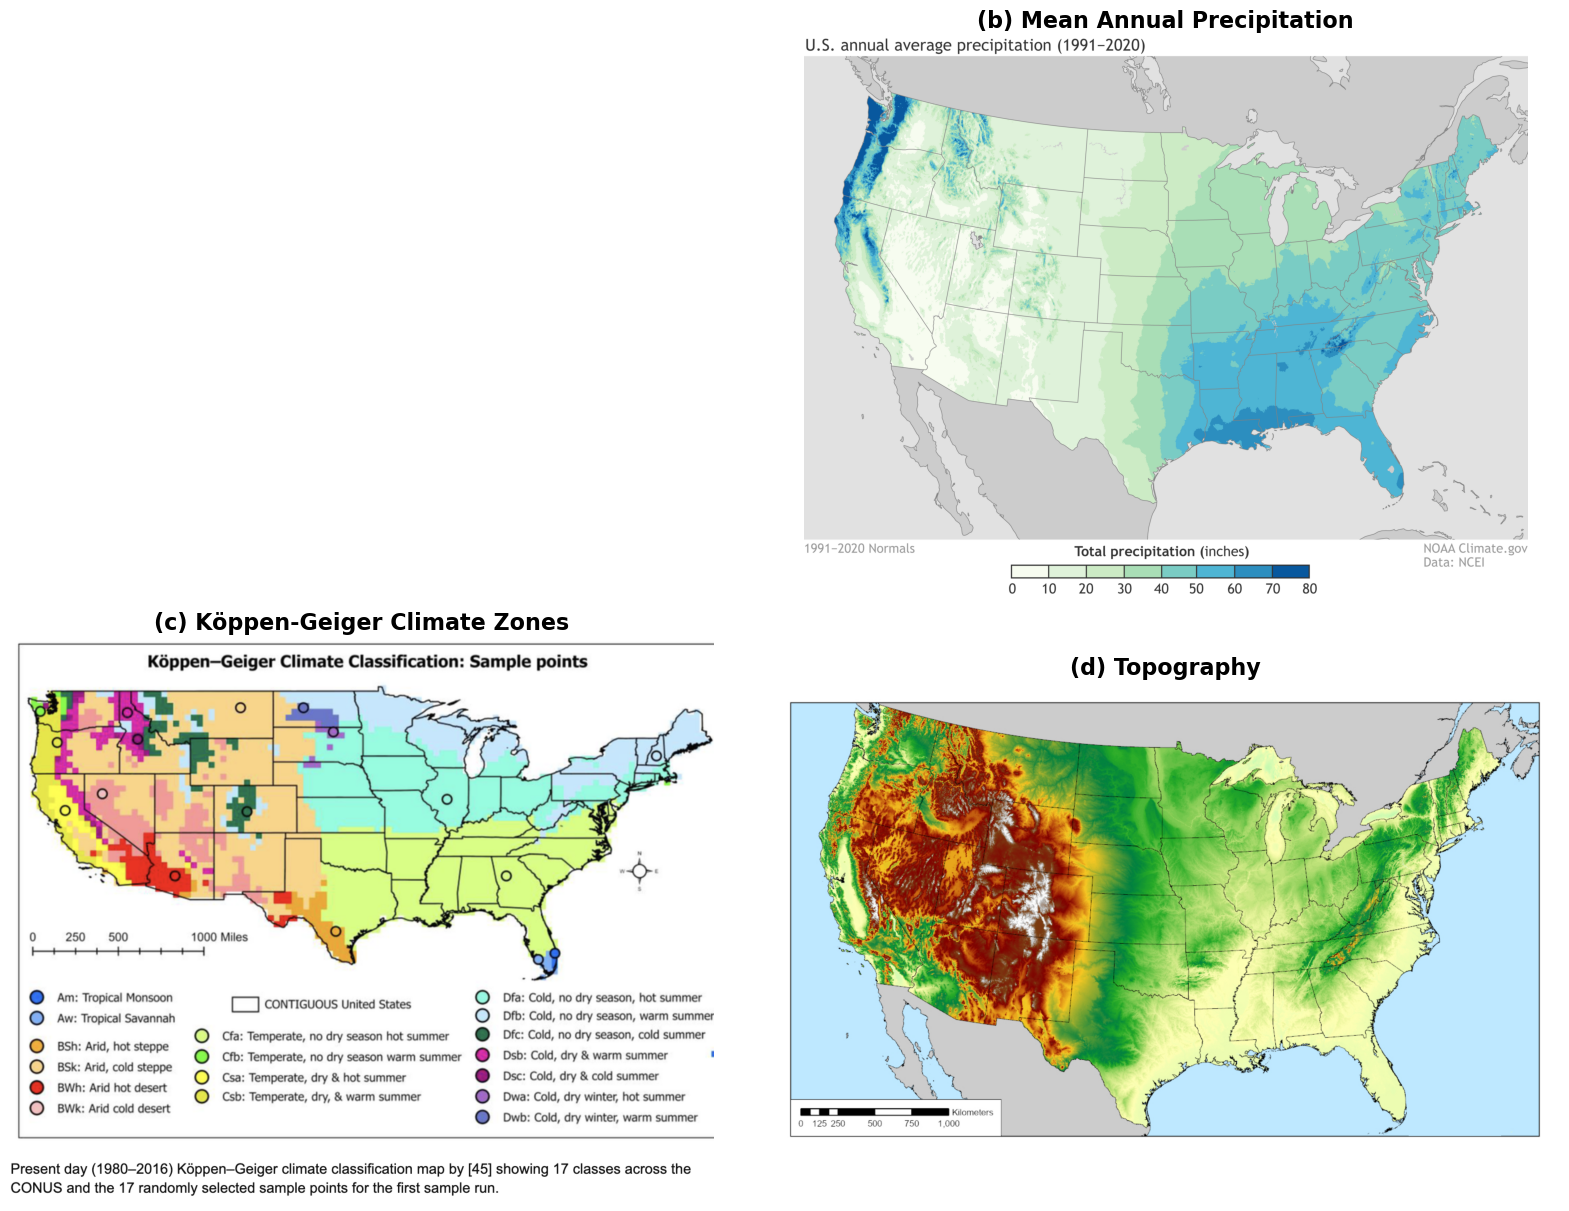

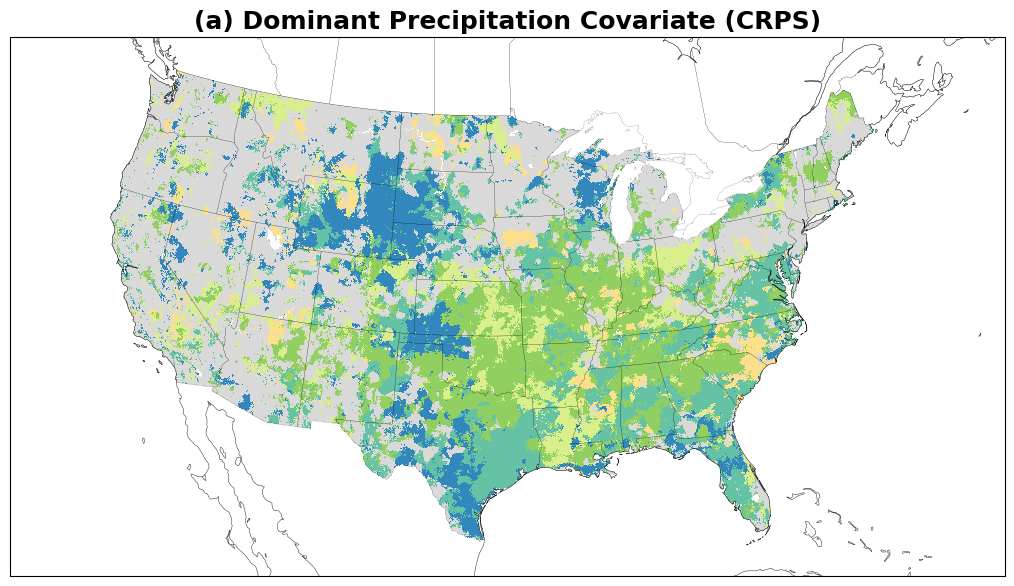

In [291]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# --------------------------------------------------
# Read images
# --------------------------------------------------

img_precip = np.array(
    Image.open("/Users/gahe5417/SCRIPTS/TXx/NOAA_AnnualPrecipitation_1991_2020.png")
)

img_koppen = np.array(
    Image.open("/Users/gahe5417/SCRIPTS/TXx/koppen_geiger.png")
)

img_topo = np.array(
    Image.open("/Users/gahe5417/SCRIPTS/TXx/CONUS-MT_2026_color_topography.jpg")
)

# --------------------------------------------------
# Figure
# --------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 12),
    constrained_layout=True,
)

# --------------------------------------------------
# (a) Dominant covariate
# --------------------------------------------------

plt.sca(axes[0, 0])

plot_categorical_map(
    dominant_CRPS.where(landmask),
    title="(a) Dominant Precipitation Covariate (CRPS)",
    cmap=dominant_cmap,
    norm=dominant_norm,
    cbar_labels=dominant_labels,
    ax=None,             # creates its own map
    proj=proj,
    state_borders=state_borders,
    rivers=None,
    show_colorbar=False,
    show_percentages=False,
)

# Remove placeholder axis
axes[0, 0].remove()

# --------------------------------------------------
# (b) Annual precipitation
# --------------------------------------------------

axes[0, 1].imshow(img_precip)
axes[0, 1].set_title(
    "(b) Mean Annual Precipitation",
    fontsize=16,
    fontweight="bold",
)
axes[0, 1].axis("off")

# --------------------------------------------------
# (c) Köppen-Geiger
# --------------------------------------------------

axes[1, 0].imshow(img_koppen)
axes[1, 0].set_title(
    "(c) Köppen-Geiger Climate Zones",
    fontsize=16,
    fontweight="bold",
)
axes[1, 0].axis("off")

# --------------------------------------------------
# (d) Topography
# --------------------------------------------------

axes[1, 1].imshow(img_topo)
axes[1, 1].set_title(
    "(d) Topography",
    fontsize=16,
    fontweight="bold",
)
axes[1, 1].axis("off")

plt.show()

https://www.researchgate.net/figure/Present-day-1980-2016-Koeppen-Geiger-climate-classification-map-by-45-showing-17_fig2_376483233 <br>
topographie USGS